# Imagery and Bleaching Analysis (benthic masks, cloud masking, outliers)

In [56]:
import ee
import os
import xee
import geemap
import folium
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import hvplot.xarray  # noqa
from tqdm.notebook import tqdm
import h5netcdf
import netCDF4
import h5py
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import f_oneway
from datetime import datetime
from matplotlib.backends.backend_pdf import PdfPages
import math
from matplotlib.colors import ListedColormap, BoundaryNorm

## Inputs

In [90]:
outlier_threshold = 1000
SID = 'SID_9d85f2d2-d654-4915-a56e-ca3ed1fd0a78'

In [91]:
file_path = fr'C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\data\nc\{SID}.nc'

df = xr.open_dataset(file_path)

In [92]:
df = df.sortby('time')
print(df.time.values[:5])   # first 5 timestamps
print(df.time.values[-5:])  # last 5 timestamps

['2017-05-21T20:29:52.652000000' '2017-09-18T20:29:45.843000000'
 '2018-02-25T20:29:46.551000000' '2018-05-21T20:29:47.641000000'
 '2018-12-17T20:29:44.000000000']
['2026-07-08T20:29:48.407000000' '2026-07-13T20:29:50.746000000'
 '2026-07-18T20:29:50.083000000' '2026-07-23T20:29:51.601000000'
 '2026-07-28T20:29:50.370000000']


In [93]:
# Check for NaN values in the dataset
NaNs = df.isnull().sum()
print("NaN counts per variable:")
print(NaNs)

NaN counts per variable:
<xarray.Dataset> Size: 64B
Dimensions:      ()
Coordinates:
    spatial_ref  int64 8B ...
Data variables:
    blue         int64 8B 0
    green        int64 8B 0
    red          int64 8B 0
    nir          int64 8B 0
    geomorphic   int64 8B 0
    benthic      int64 8B 0
    reef_mask    int64 8B 0
Attributes:
    stac:                 https://earthengine-stac.storage.googleapis.com/cat...
    epsg:                 32705
    resolution:           10
    edge_size:            256
    edge_size_m:          2560
    central_lat:          -16.539667
    central_lon:          -151.788722
    central_y:            8170979.177077682
    central_x:            629251.0882932513
    time_coverage_start:  2017-04-01
    time_coverage_end:    2026-08-01


In [94]:
# benthic classes: 0 unmapped;11 sand; 12 rubble; 13 rock; 14 seagrass; 15 coral; 18 microalgal mats

# change benthic unmapped pixels back to 0 from 255
df['benthic'] = df['benthic'].where(df['benthic'] != 255, 0)

# If benthic has no time dimension:
benthic_data = df['benthic'].values

# If benthic has a time dimension, select one slice:
# benthic_data = df['benthic'].isel(time=0).values

# Get unique values and their counts
unique_vals, counts = np.unique(benthic_data, return_counts=True)

# Combine into a dict or just print
for val, count in zip(unique_vals, counts):
    print(f"Value {val}: {count} pixels")

Value 0: 28072 pixels
Value 11: 23231 pixels
Value 12: 4973 pixels
Value 13: 2461 pixels
Value 15: 4086 pixels
Value 18: 2713 pixels


## Benthic Mask

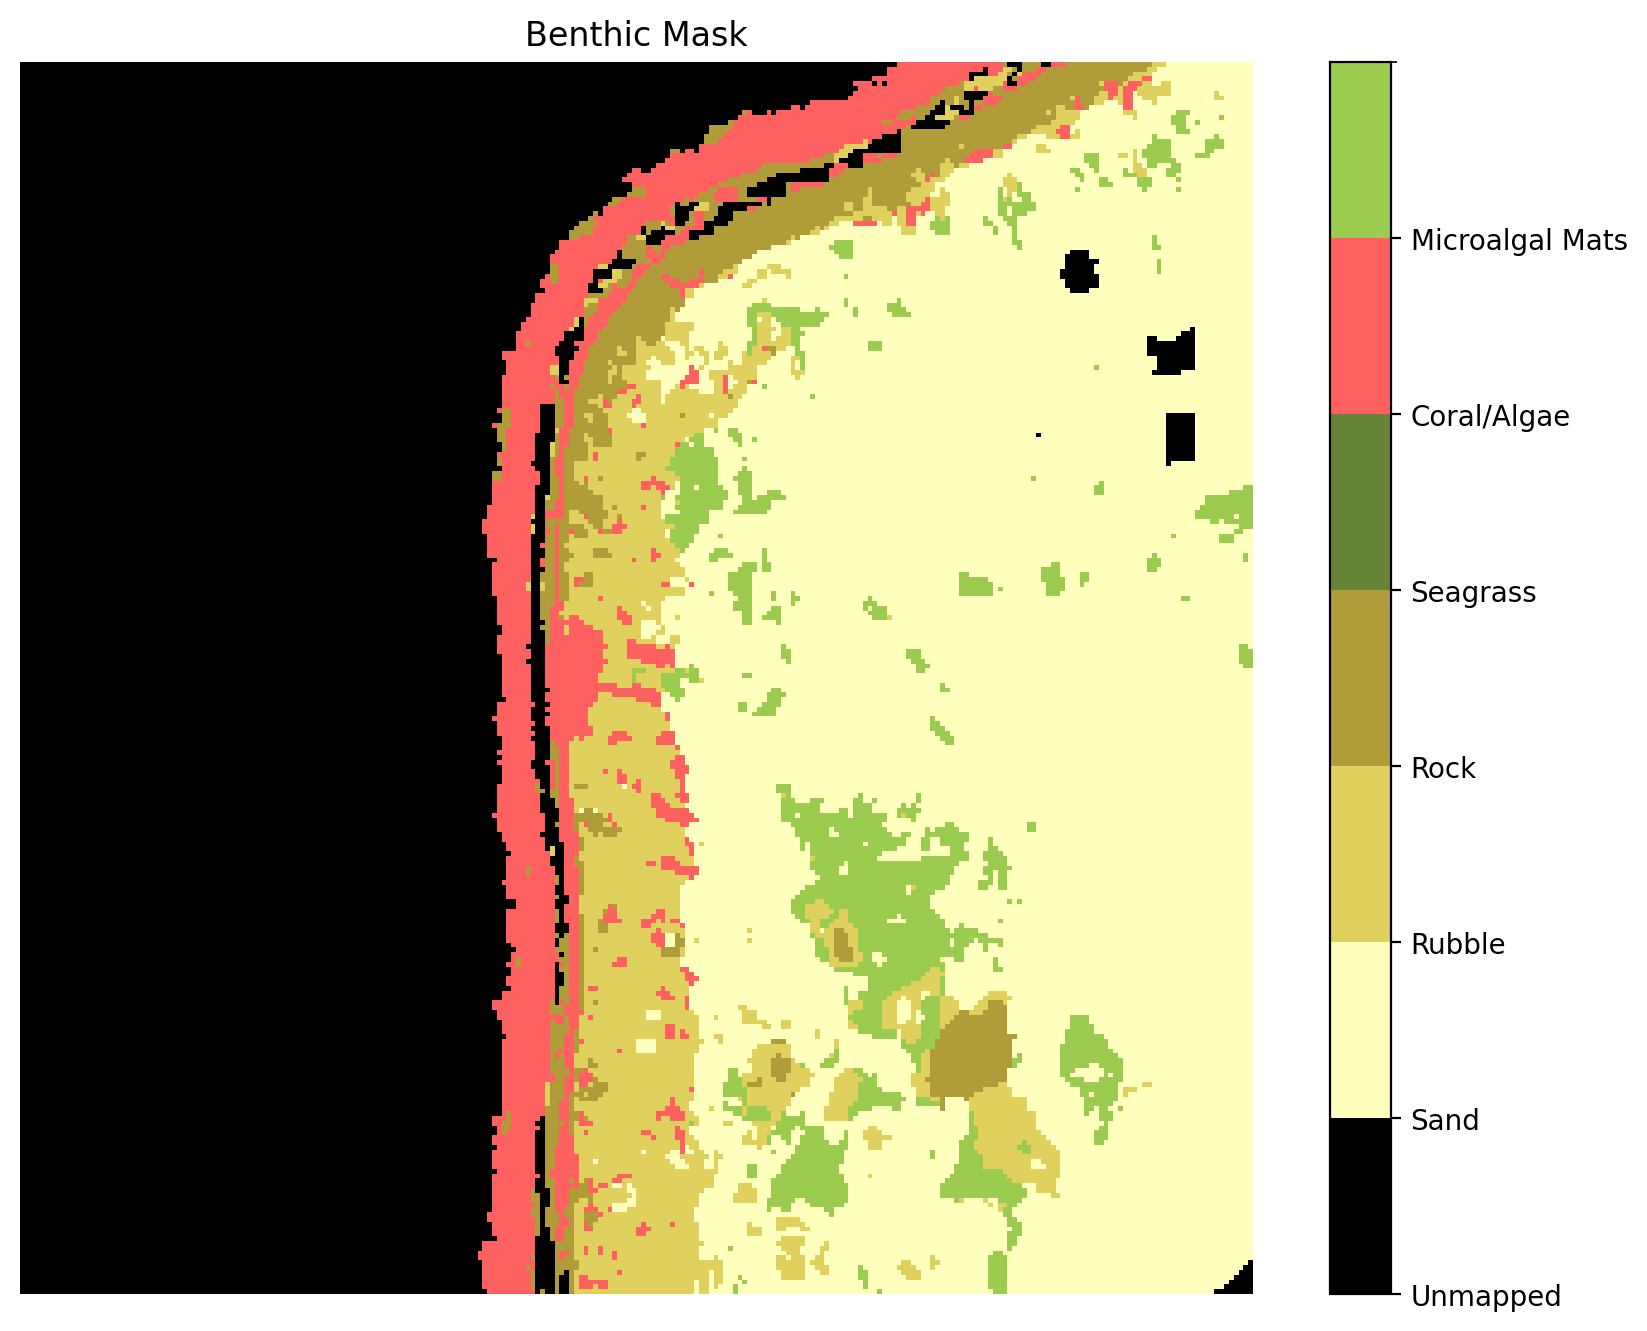

In [95]:
benthic = df['benthic']

color_dict = {
    0: "#000000",    # Unmapped
    11: "#ffffbe",   # Sand
    12: "#e0d05e",   # Rubble
    13: "#b19c3a",   # Rock
    14: "#668438",   # Seagrass
    15: "#ff6161",   # Coral/Algae
    18: "#9bcc4f"    # Microalgal Mats
}

# Create a list of all possible values in order
classes = list(color_dict.keys())
colors = [color_dict[k] for k in classes]

# Set up the colormap and normalization
cmap = ListedColormap(colors)
norm = BoundaryNorm(classes + [max(classes) + 1], cmap.N)

# Plot the data (selecting a time slice if needed)
plt.figure(figsize=(10, 8))
im = plt.imshow(benthic.values, cmap=cmap, norm=norm)
plt.title("Benthic Mask")
cbar = plt.colorbar(im, ticks=classes)
cbar.ax.set_yticklabels([
    "Unmapped", "Sand", "Rubble", "Rock", "Seagrass", "Coral/Algae", "Microalgal Mats"
])
plt.axis('off')
# Save plot to the requested output folder
output_dir = r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\nc_analysis"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(os.path.join(output_dir, f"{SID}_benthic_mask.pdf"), bbox_inches='tight')
plt.show()

## Create PDF with all Sentinel images

Compute percentiles across channels for ALL pixels and clip each time slice to increase image contrast while maintaining hue.

In [96]:
# Step 1: Define global shared clipping range from all RGB pixels (calculates shared lower and upper brightness limits for all RGB data)
def global_clip(df, pmin, pmax):
    r = df.red.values.flatten()
    g = df.green.values.flatten()
    b = df.blue.values.flatten()
    stacked = np.concatenate([r[~np.isnan(r)], g[~np.isnan(g)], b[~np.isnan(b)]])
    return np.percentile(stacked, [pmin, pmax]) # clipping is used to improve image contrast

In [97]:
#Step 2: Define plotting function

def plot_slice(df, time_index, clip_min, clip_max, ax=None):
    red = df.red.isel(time=time_index)
    green = df.green.isel(time=time_index)
    blue = df.blue.isel(time=time_index)

    # Normalize using global clip range
    def normalize(band):
        return ((band - clip_min).clip(0, clip_max - clip_min)) / (clip_max - clip_min)

    red_norm = normalize(red)
    green_norm = normalize(green)
    blue_norm = normalize(blue)

    # Stack RGB
    rgb = xr.concat([red_norm, green_norm, blue_norm], dim='band')
    rgb = rgb.assign_coords(band=['red', 'green', 'blue'])
    rgb = rgb.transpose('y', 'x', 'band')
    rgb_np = np.nan_to_num(rgb.values, nan=0.0)

    # Plot to given axis or default
    if ax is None:
        ax = plt.gca()
    
    ax.imshow(rgb_np)
    ax.set_title(pd.to_datetime(df.time.values[time_index]).date(), fontsize=8)
    ax.axis('off')

In [98]:
#Step 3: Apply global clip and plot functions into tiled pdf

clip_min, clip_max = global_clip(df, pmin=15, pmax=96) # 15th and 96th percentiles for global clipping
num_images = len(df.time)
tiles_per_page = 96
rows, cols = 12, 8
num_pages = math.ceil(num_images / tiles_per_page)

# increase resolution and avoid interpolation blur
plt.rcParams['figure.dpi'] = 200
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['image.interpolation'] = 'nearest'

# force larger figure size for the tiled pages (override figsize passed to plt.subplots)
_orig_subplots = plt.subplots
def _subplots(*args, **kwargs):
    kwargs['figsize'] = (24, 24)
    fig, axes = _orig_subplots(*args, **kwargs)
    fig.set_dpi(200)
    return fig, axes
plt.subplots = _subplots



with PdfPages(os.path.join(output_dir, f"{SID}_all_rgb.pdf")) as pdf: 
    for page in tqdm(range(num_pages), desc="Creating PDF pages"):
        fig, axes = plt.subplots(rows, cols, figsize=(12, 12))
        axes = axes.flatten()

        for i in range(tiles_per_page):
            time_idx = page * tiles_per_page + i
            if time_idx >= num_images:
                axes[i].axis('off')
                continue
            plot_slice(df, time_index=time_idx, clip_min=clip_min, clip_max=clip_max, ax=axes[i])

        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

Creating PDF pages:   0%|          | 0/5 [00:00<?, ?it/s]

In [99]:
print(f"Global shared clip range: {clip_min:.1f} – {clip_max:.1f}")

Global shared clip range: 0.0 – 2710.0


In [100]:
dates = pd.to_datetime(df.time.values)
print(dates[dates.duplicated(keep=False)])

DatetimeIndex([], dtype='datetime64[ns]', freq=None)


## Histogram

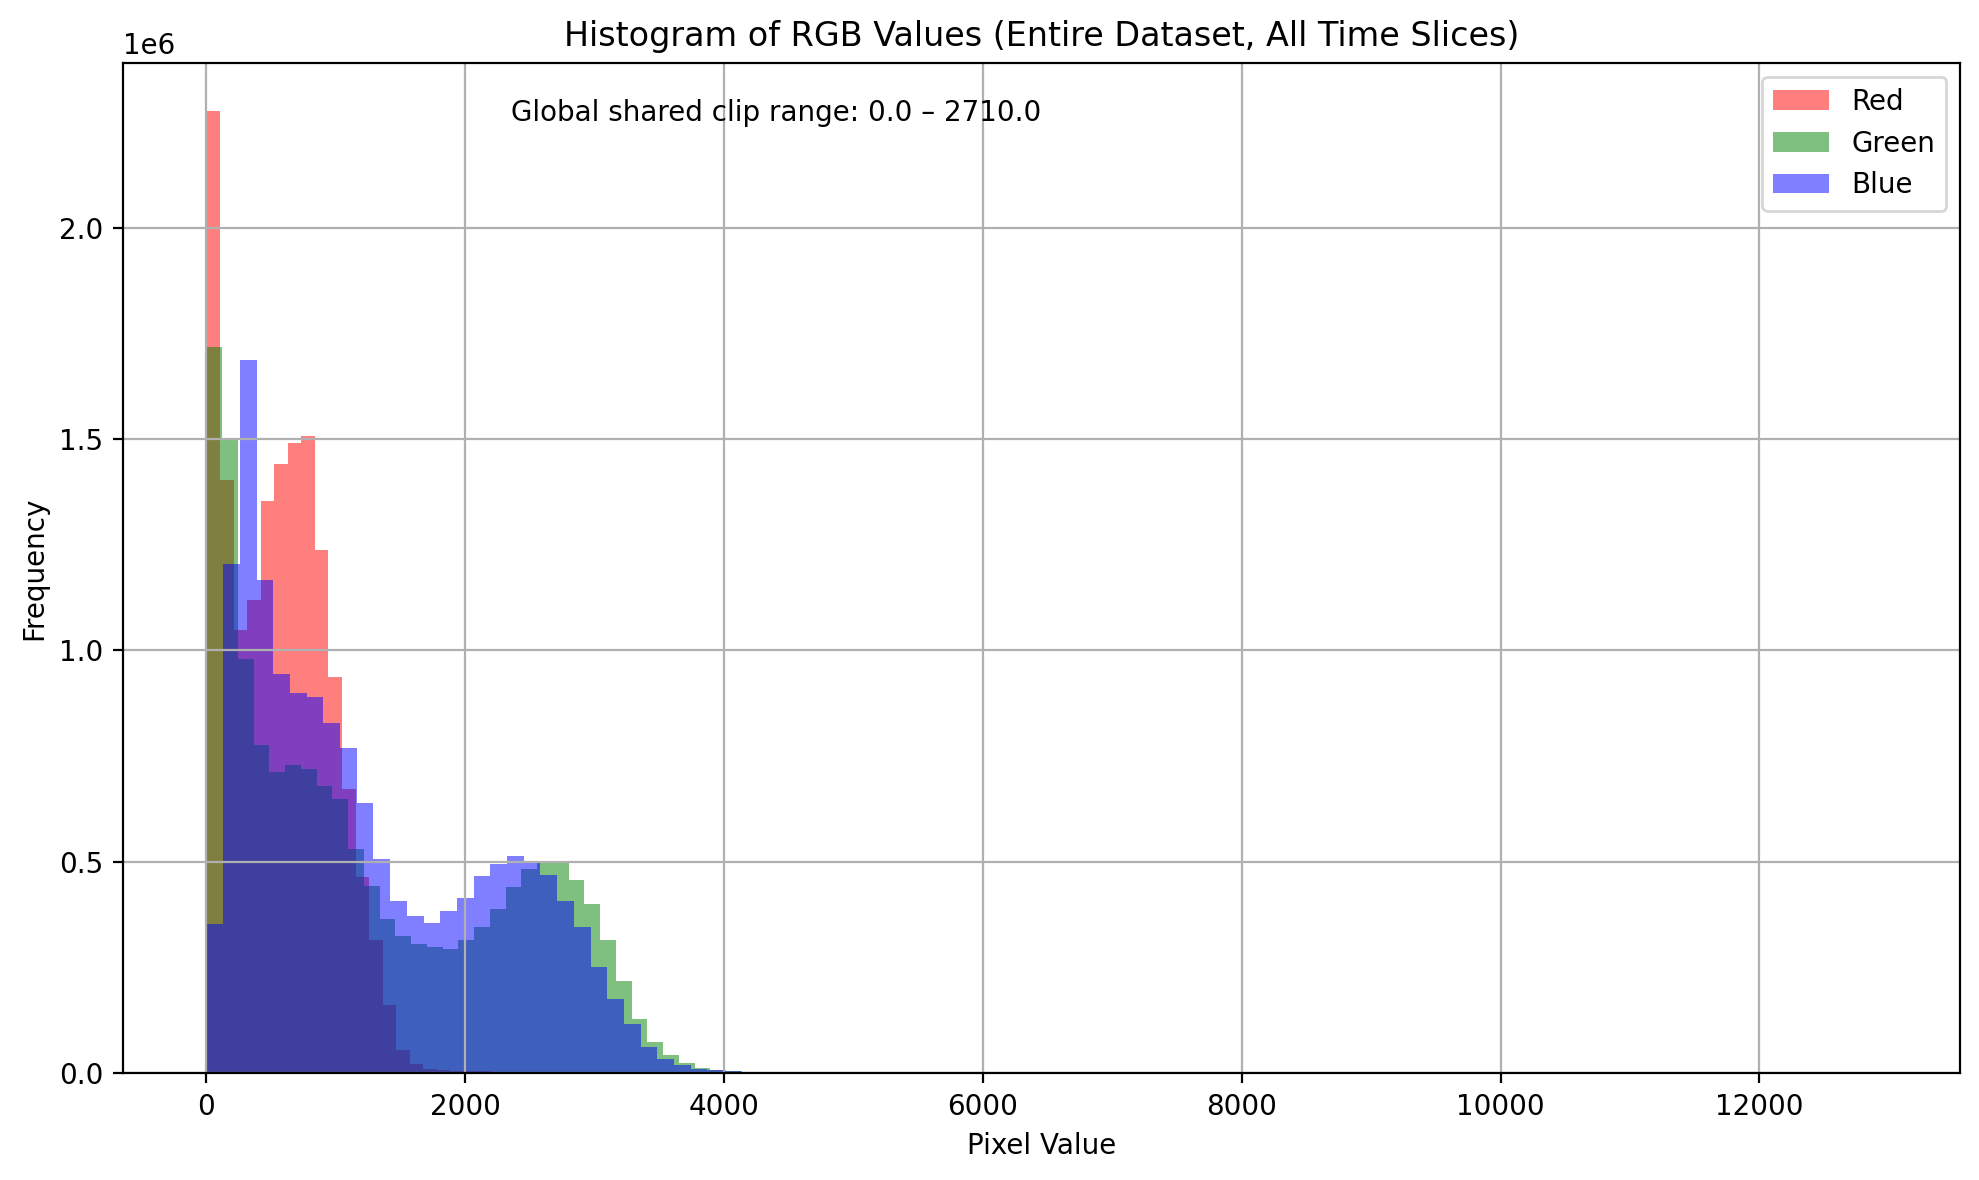

In [101]:
# Extract values across all time slices
red_vals = df.red.values
green_vals = df.green.values
blue_vals = df.blue.values

# Flatten and remove not valid
r = red_vals[np.isfinite(red_vals) & (red_vals > 0)].flatten()
g = green_vals[np.isfinite(green_vals) & (green_vals > 0)].flatten()
b = blue_vals[np.isfinite(blue_vals) & (blue_vals > 0)].flatten()

# Plot histograms
plt.figure(figsize=(10, 6))
plt.hist(r, bins=100, color='red', alpha=0.5, label='Red')
plt.hist(g, bins=100, color='green', alpha=0.5, label='Green')
plt.hist(b, bins=100, color='blue', alpha=0.5, label='Blue')

# Add clip range text to plot (adjust x/y as needed)
clip_text = f"Global shared clip range: {clip_min:.1f} – {clip_max:.1f}"
plt.text(0.5, 0.95, clip_text, fontsize=10, ha='right', va='center', transform=plt.gca().transAxes)

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.title('Histogram of RGB Values (Entire Dataset, All Time Slices)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"{SID}_all_histogram.pdf"), bbox_inches='tight')
plt.show()

## Create PDF with all Sentinel images (only coral)

Compute percentiles across channels for CORAL pixels and clip each time slice to increase image contrast while maintaining hue.

In [102]:
# Step 1: Compute shared clipping range using only benthic == 15 pixels
def global_clip_benthic15(df, pmin, pmax):
    mask = df.benthic == 15

    r = df.red.where(mask).values.flatten()
    g = df.green.where(mask).values.flatten()
    b = df.blue.where(mask).values.flatten()

    stacked = np.concatenate([
        r[~np.isnan(r)],
        g[~np.isnan(g)],
        b[~np.isnan(b)]
    ])
    
    return np.percentile(stacked, [pmin, pmax])

In [103]:
# Step 2: Plot one time slice using the benthic==15 mask and shared clip range
def plot_slice_benthic15(df, time_index, clip_min, clip_max, ax=None, outlier_threshold=outlier_threshold):
    mask = df.benthic == 15

    red = df.red.isel(time=time_index).where(mask)
    green = df.green.isel(time=time_index).where(mask)
    blue = df.blue.isel(time=time_index).where(mask)

    def normalize(band):
        return ((band - clip_min).clip(0, clip_max - clip_min)) / (clip_max - clip_min)

    red_norm = normalize(red)
    green_norm = normalize(green)
    blue_norm = normalize(blue)

    rgb = xr.concat([red_norm, green_norm, blue_norm], dim='band')
    rgb = rgb.assign_coords(band=['red', 'green', 'blue'])
    rgb = rgb.transpose('y', 'x', 'band')
    rgb_np = np.nan_to_num(rgb.values, nan=0.0)

  # Plot to given axis or default
    if ax is None:
        ax = plt.gca()
    
    ax.imshow(rgb_np)



    # mark outliers in red
    red_raw = df.red.isel(time=time_index).values
    green_raw = df.green.isel(time=time_index).values
    blue_raw = df.blue.isel(time=time_index).values
    nir_raw = df.nir.isel(time=time_index).values

    coral_mask = df.benthic.values == 15

    # mask outliers: outlier if all vis bands and nir exceed threshold because such pixels are likely glint or clouds
    outlier_mask = coral_mask & (
        (red_raw > outlier_threshold)
        & (green_raw > outlier_threshold)
        & (blue_raw > outlier_threshold)
        & (nir_raw > outlier_threshold)
    )

    outlier_overlay = np.zeros((*outlier_mask.shape, 4), dtype=float) 
    outlier_overlay[outlier_mask] = [1.0, 0.0, 0.0, 0.95]

    ax.imshow(
        outlier_overlay,
        interpolation="nearest",
        zorder=2
    )




    ax.set_title(pd.to_datetime(df.time.values[time_index]).date(), fontsize=8)
    ax.axis('off')

In [104]:

# Step 3: Apply global clip and plot functions into tiled pdf
clip_min, clip_max = global_clip_benthic15(df, pmin=15, pmax=96)
num_images = len(df.time)
tiles_per_page = 96
rows, cols = 12, 8
num_pages = math.ceil(num_images / tiles_per_page)

with PdfPages(os.path.join(output_dir, f"{SID}_coral_rgb.pdf")) as pdf:
    for page in tqdm(range(num_pages), desc="Creating PDF pages"):
        fig, axes = plt.subplots(rows, cols, figsize=(12, 12))
        axes = axes.flatten()

        for i in range(tiles_per_page):
            time_idx = page * tiles_per_page + i
            if time_idx >= num_images:
                axes[i].axis('off')
                continue
            plot_slice_benthic15(df, time_index=time_idx, clip_min=clip_min, clip_max=clip_max, ax=axes[i], outlier_threshold=outlier_threshold)

        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

Creating PDF pages:   0%|          | 0/5 [00:00<?, ?it/s]

In [105]:
print(f"Shared clip range (benthic=15): {clip_min:.1f} – {clip_max:.1f}")

Shared clip range (benthic=15): 0.0 – 2466.0


## Histogram (only coral)

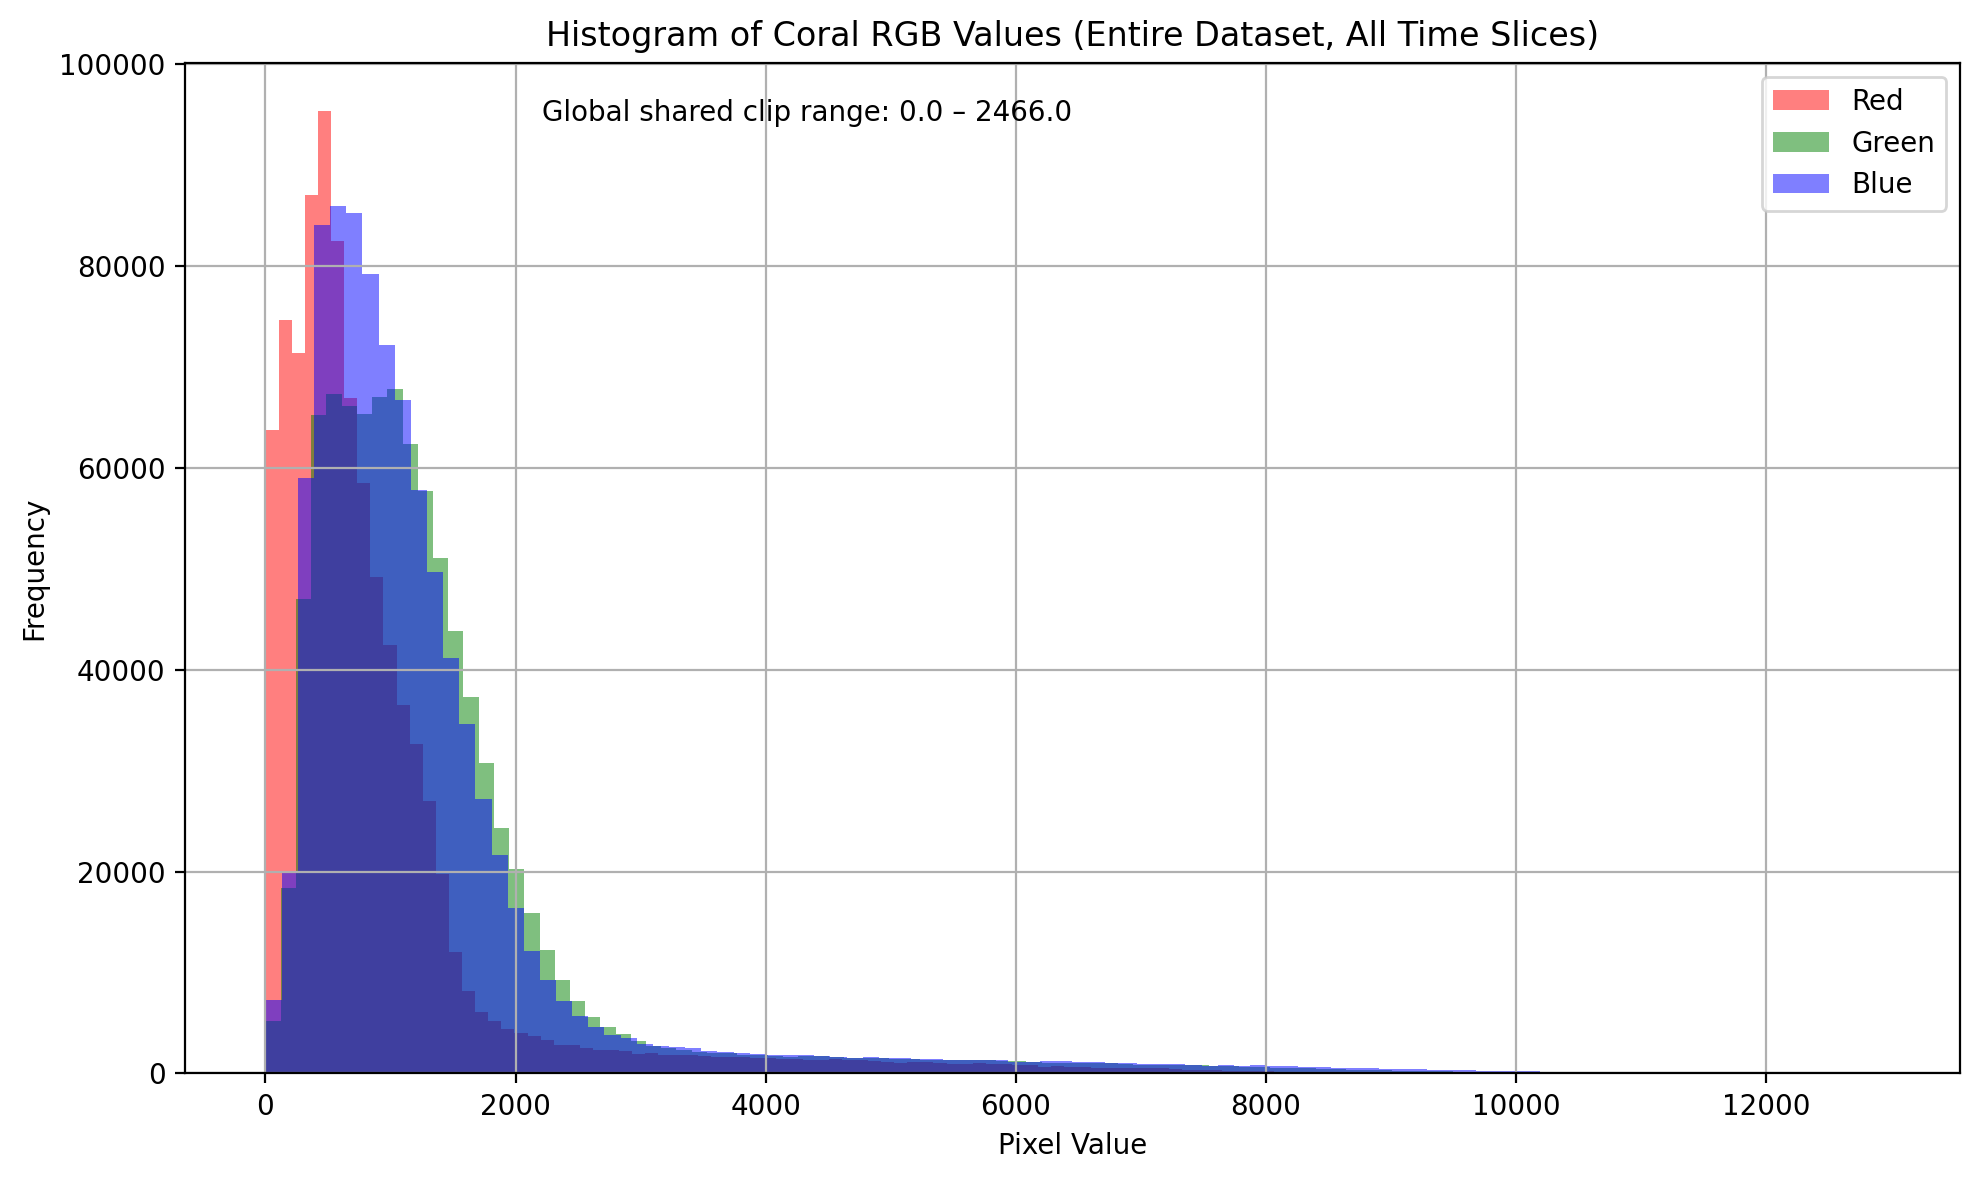

In [106]:
# Extract values across all time slices
mask = df.benthic == 15

r = df.red.where(mask).values.flatten()
g = df.green.where(mask).values.flatten()
b = df.blue.where(mask).values.flatten()

r = r[np.isfinite(r) & (r > 0)]
g = g[np.isfinite(g) & (g > 0)]
b = b[np.isfinite(b) & (b > 0)]

# Plot histograms
plt.figure(figsize=(10, 6))
plt.hist(r, bins=100, color='red', alpha=0.5, label='Red')
plt.hist(g, bins=100, color='green', alpha=0.5, label='Green')
plt.hist(b, bins=100, color='blue', alpha=0.5, label='Blue')

# Add clip range text to plot (adjust x/y as needed)
clip_text = f"Global shared clip range: {clip_min:.1f} – {clip_max:.1f}"
plt.text(0.5, 0.95, clip_text, fontsize=10, ha='right', va='center', transform=plt.gca().transAxes)

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.title('Histogram of Coral RGB Values (Entire Dataset, All Time Slices)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"{SID}_coral_histogram.pdf"), bbox_inches='tight')
plt.show()

In [107]:
# print min, max, 1st percentile, median, 99th percentile, and 99.9th percentile for each channel to inspect suspicious values in coral pixels

for channel in ["blue", "green", "red"]:
    mask = df.benthic == 15
    values = df[channel].where(mask).values
    values = values[np.isfinite(values)]
    values = values[values > 0]

    print(f"\n{channel}")
    print("min:", np.min(values))
    print("max:", np.max(values))
    print("p1:", np.percentile(values, 1))
    print("p50:", np.percentile(values, 50))
    print("p99:", np.percentile(values, 99))
    print("p99.9:", np.percentile(values, 99.9))


blue
min: 1.0
max: 12904.0
p1: 149.0
p50: 974.0
p99: 7848.0
p99.9: 10056.0

green
min: 1.0
max: 12168.0
p1: 163.0
p50: 1080.0
p99: 7363.6875
p99.9: 9392.0

red
min: 1.0
max: 10472.0
p1: 6.0
p50: 610.0
p99: 6176.0
p99.9: 8012.0


## Sentinel Acquisition Analysis

Number of acquisitions: 467


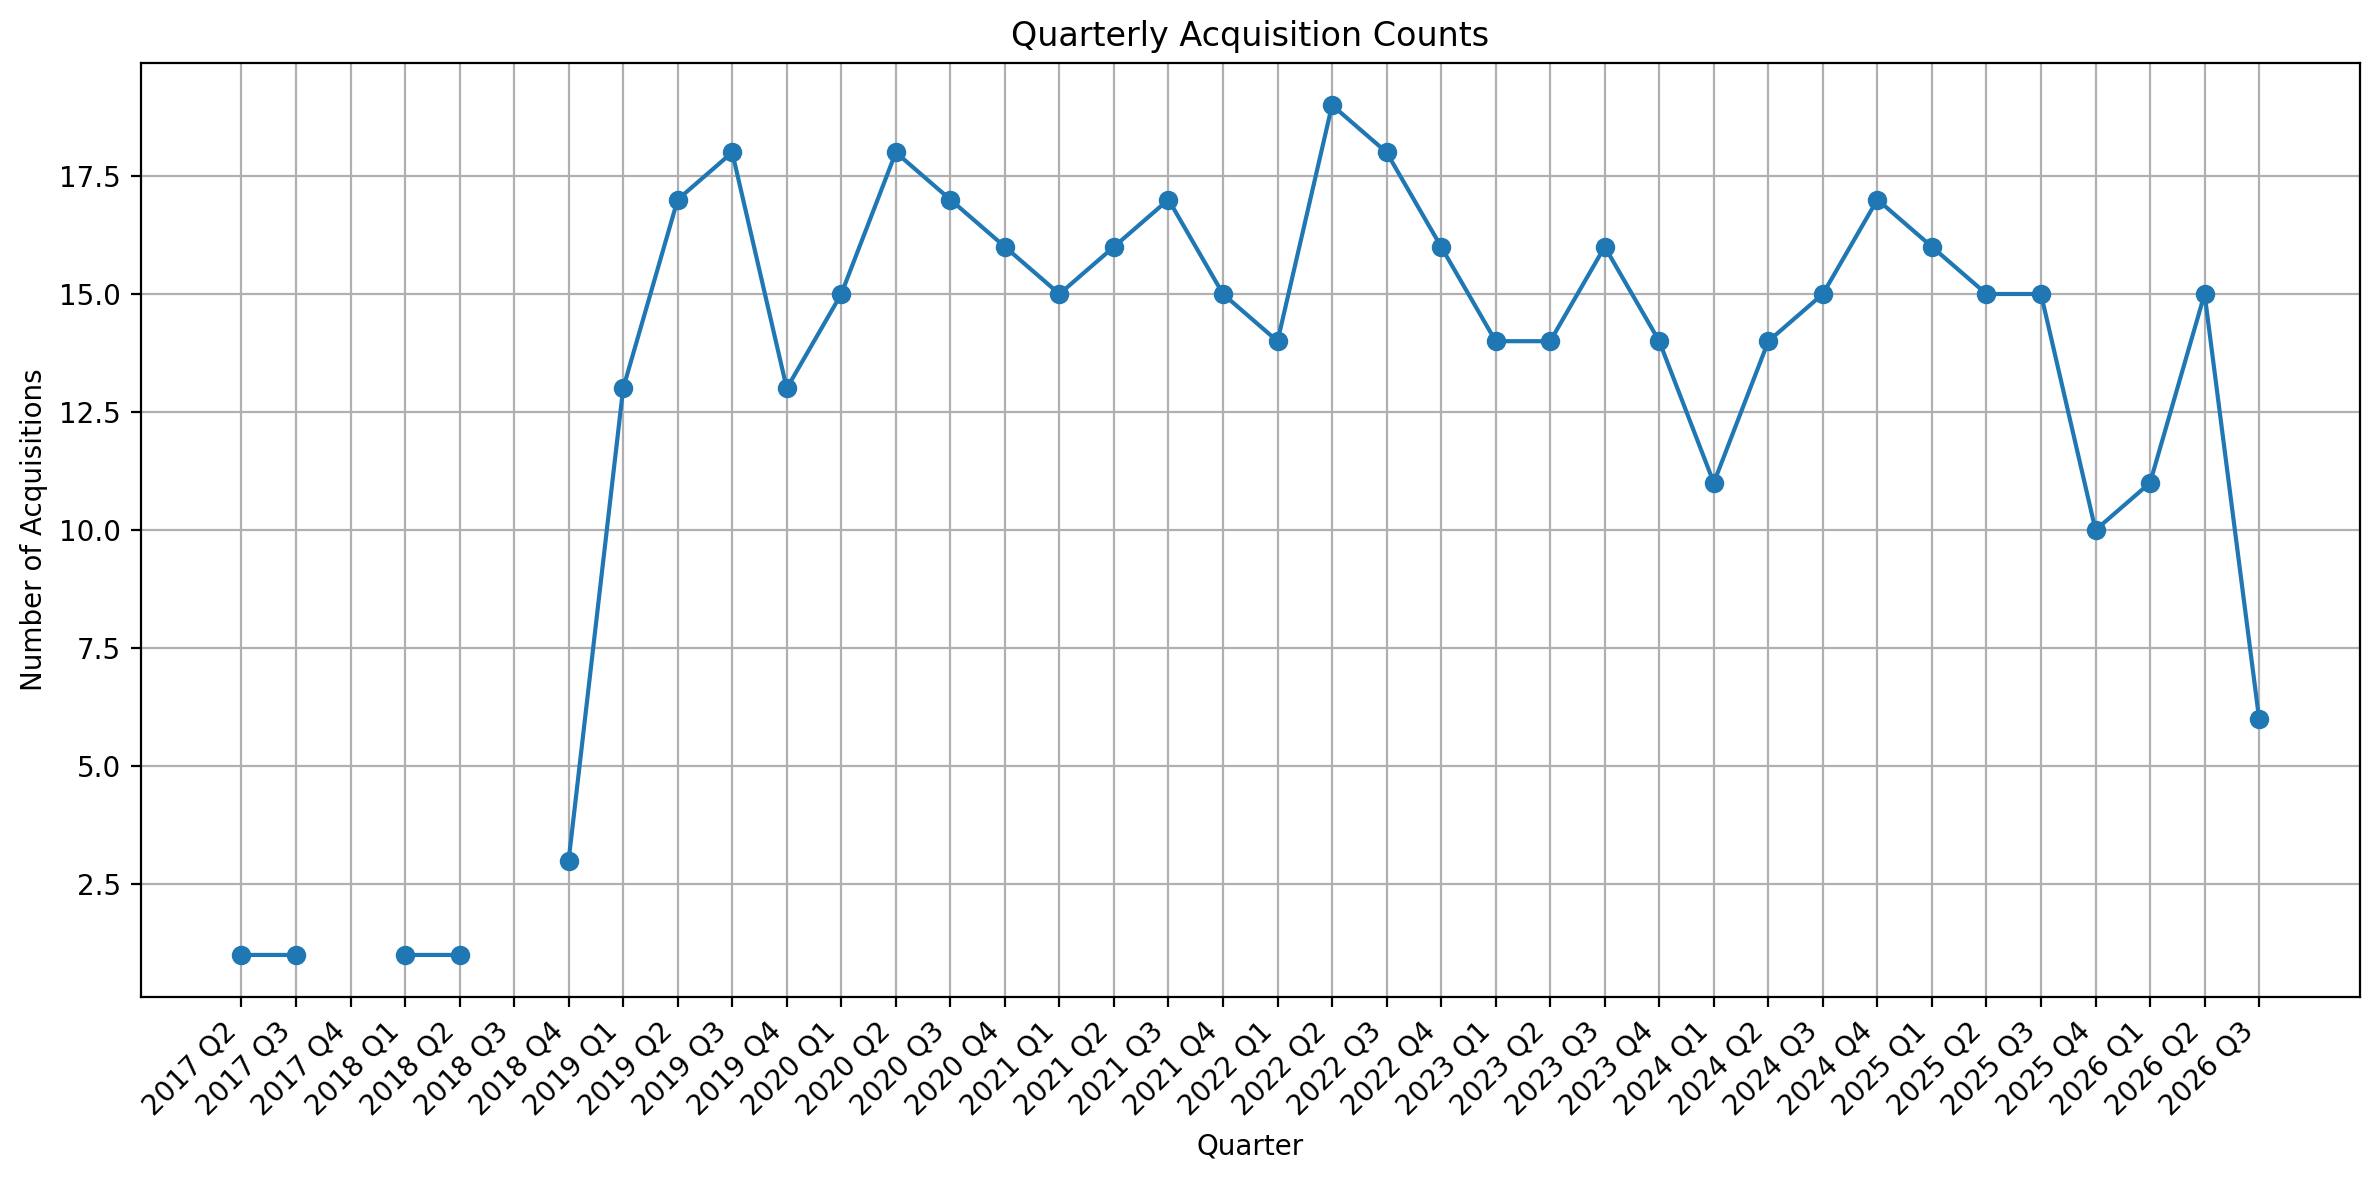

In [108]:
# plot quarterly acquisition counts and gaps between acquisitions

print("Number of acquisitions:", len(df.time))

quarter_counts = df.time.resample(time="QS").count()

quarter_dates = pd.to_datetime(quarter_counts.time.values)
quarter_labels = [
    f"{date.year} Q{date.quarter}"
    for date in quarter_dates
]

plt.subplots = _orig_subplots
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    range(len(quarter_counts)),
    quarter_counts.values,
    marker="o"
)

ax.set_xticks(range(len(quarter_counts)))
ax.set_xticklabels(quarter_labels, rotation=45, ha="right")


ax.set_xlabel("Quarter")
ax.set_ylabel("Number of Acquisitions")
ax.set_title("Quarterly Acquisition Counts")
ax.grid(True)

plt.tight_layout()
plt.show()

## Check SCL cloud masking and Cloud_probabaility masking

In [109]:
ee.Initialize(project='glassy-acolyte-480612-n3')

In [110]:
regions = pd.read_parquet(
    r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\sentinelregions.parquet"
)

site_id = SID.removeprefix("SID_")

site = regions.loc[
    regions["Site_ID"].astype(str) == site_id
].iloc[0]

lat = float(site["lat"])
lon = float(site["lon"])

point = ee.Geometry.Point([lon, lat])

In [111]:
S2_CLOUD_PROBABILITY_THRESHOLD = 30


def mask_s2(image):
    scl = image.select("SCL")
    cloud_probability = ee.Image(image.get("cloud_probability")).select("probability")

    valid = (
        scl.neq(1)  # Saturated or defective
        .And(scl.neq(2))  # Dark Area Pixels
        .And(scl.neq(3))  # Cloud Shadows
        .And(scl.neq(7))  # Clouds Low Probability
        .And(scl.neq(8))  # Clouds Medium Probability
        .And(scl.neq(9))  # Clouds High Probability
        .And(scl.neq(10))  # Cirrus
        .And(scl.neq(11))  # Snow / Ice
    )

    valid = valid.And(cloud_probability.lt(S2_CLOUD_PROBABILITY_THRESHOLD))
    return image.updateMask(valid)


sr_collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(point)
    .filterDate("2019-10-26", "2019-10-29")  # choose daterange to investigate #2020-01-01", "2021-01-31
)

cloud_probability_collection = (
    ee.ImageCollection("COPERNICUS/S2_CLOUD_PROBABILITY")
    .filterBounds(point)
    .filterDate("2019-10-26", "2019-10-29")  # choose daterange to investigate
)

joined_collection = ee.Join.saveFirst("cloud_probability").apply(
    primary=sr_collection,
    secondary=cloud_probability_collection,
    condition=ee.Filter.equals(
        leftField="system:index",
        rightField="system:index",
    ),
)

# Keep only images that have a matching cloud probability tile.
test_collection = (
    ee.ImageCollection(joined_collection)
    .filter(ee.Filter.notNull(["cloud_probability"]))
    .sort("CLOUDY_PIXEL_PERCENTAGE")
)

image = ee.Image(test_collection.first())  # get image with lowest cloud cover
masked_image = mask_s2(image)
cloud_probability = ee.Image(image.get("cloud_probability")).select("probability")
rejected_by_probability = cloud_probability.gte(S2_CLOUD_PROBABILITY_THRESHOLD).selfMask()

rgb = {
    "bands": ["B4", "B3", "B2"],
    "min": 0,
    "max": 3000,
}

probability_visualization = {
    "min": 0,
    "max": 100,
    "palette": ["green", "yellow", "orange", "red"],
}

Map = geemap.Map()
Map.centerObject(point, 14)  # zoom is approximately the image displayed in PDF

Map.addLayer(image, rgb, "Original")
Map.addLayer(
    masked_image.unmask(0),  # fill masked pixels with black
    rgb,
    "SCL masked + cloud probability masked",
)
Map.addLayer(
    cloud_probability,
    probability_visualization,
    "Cloud probability (%)",
)
Map.addLayer(
    rejected_by_probability,
    {"palette": ["red"]},
    f"Rejected by cloud probability >= {S2_CLOUD_PROBABILITY_THRESHOLD}",
)


Map

Map(center=[-16.539667, -151.788722], controls=(WidgetControl(options=['position', 'transparent_bg'], position…

## Plot median per acquisition date and band timeseries

Check if bleaching is visible in data by comparing median pixel reflectance and ground truth bleaching

In [112]:
channels = ["blue", "green", "red", "nir"]
source_scale = 10000

coral_mask = df["benthic"] == 15

outlier_mask = (
    (df["red"] > outlier_threshold)
    & (df["green"] > outlier_threshold)
    & (df["blue"] > outlier_threshold)
    & (df["nir"] > outlier_threshold)
)

valid_coral_mask = coral_mask & ~outlier_mask

spatial_dims = [dim for dim in ("y", "x") if dim in df.dims]

summary = pd.DataFrame(index=pd.to_datetime(df["time"].values))

for channel in channels:
    values = df[channel].where(
        valid_coral_mask & (df[channel] > 0) # only valid pixels
    )

    summary[f"{channel}_mean"] = (
        values.mean(dim=spatial_dims, skipna=True).values / source_scale
    )

    summary[f"{channel}_median"] = (
        values.median(dim=spatial_dims, skipna=True).values / source_scale
    )

valid = df["blue"].where(
    valid_coral_mask & (df["blue"] > 0)
)

summary["n_valid"] = valid.count(dim=spatial_dims).values

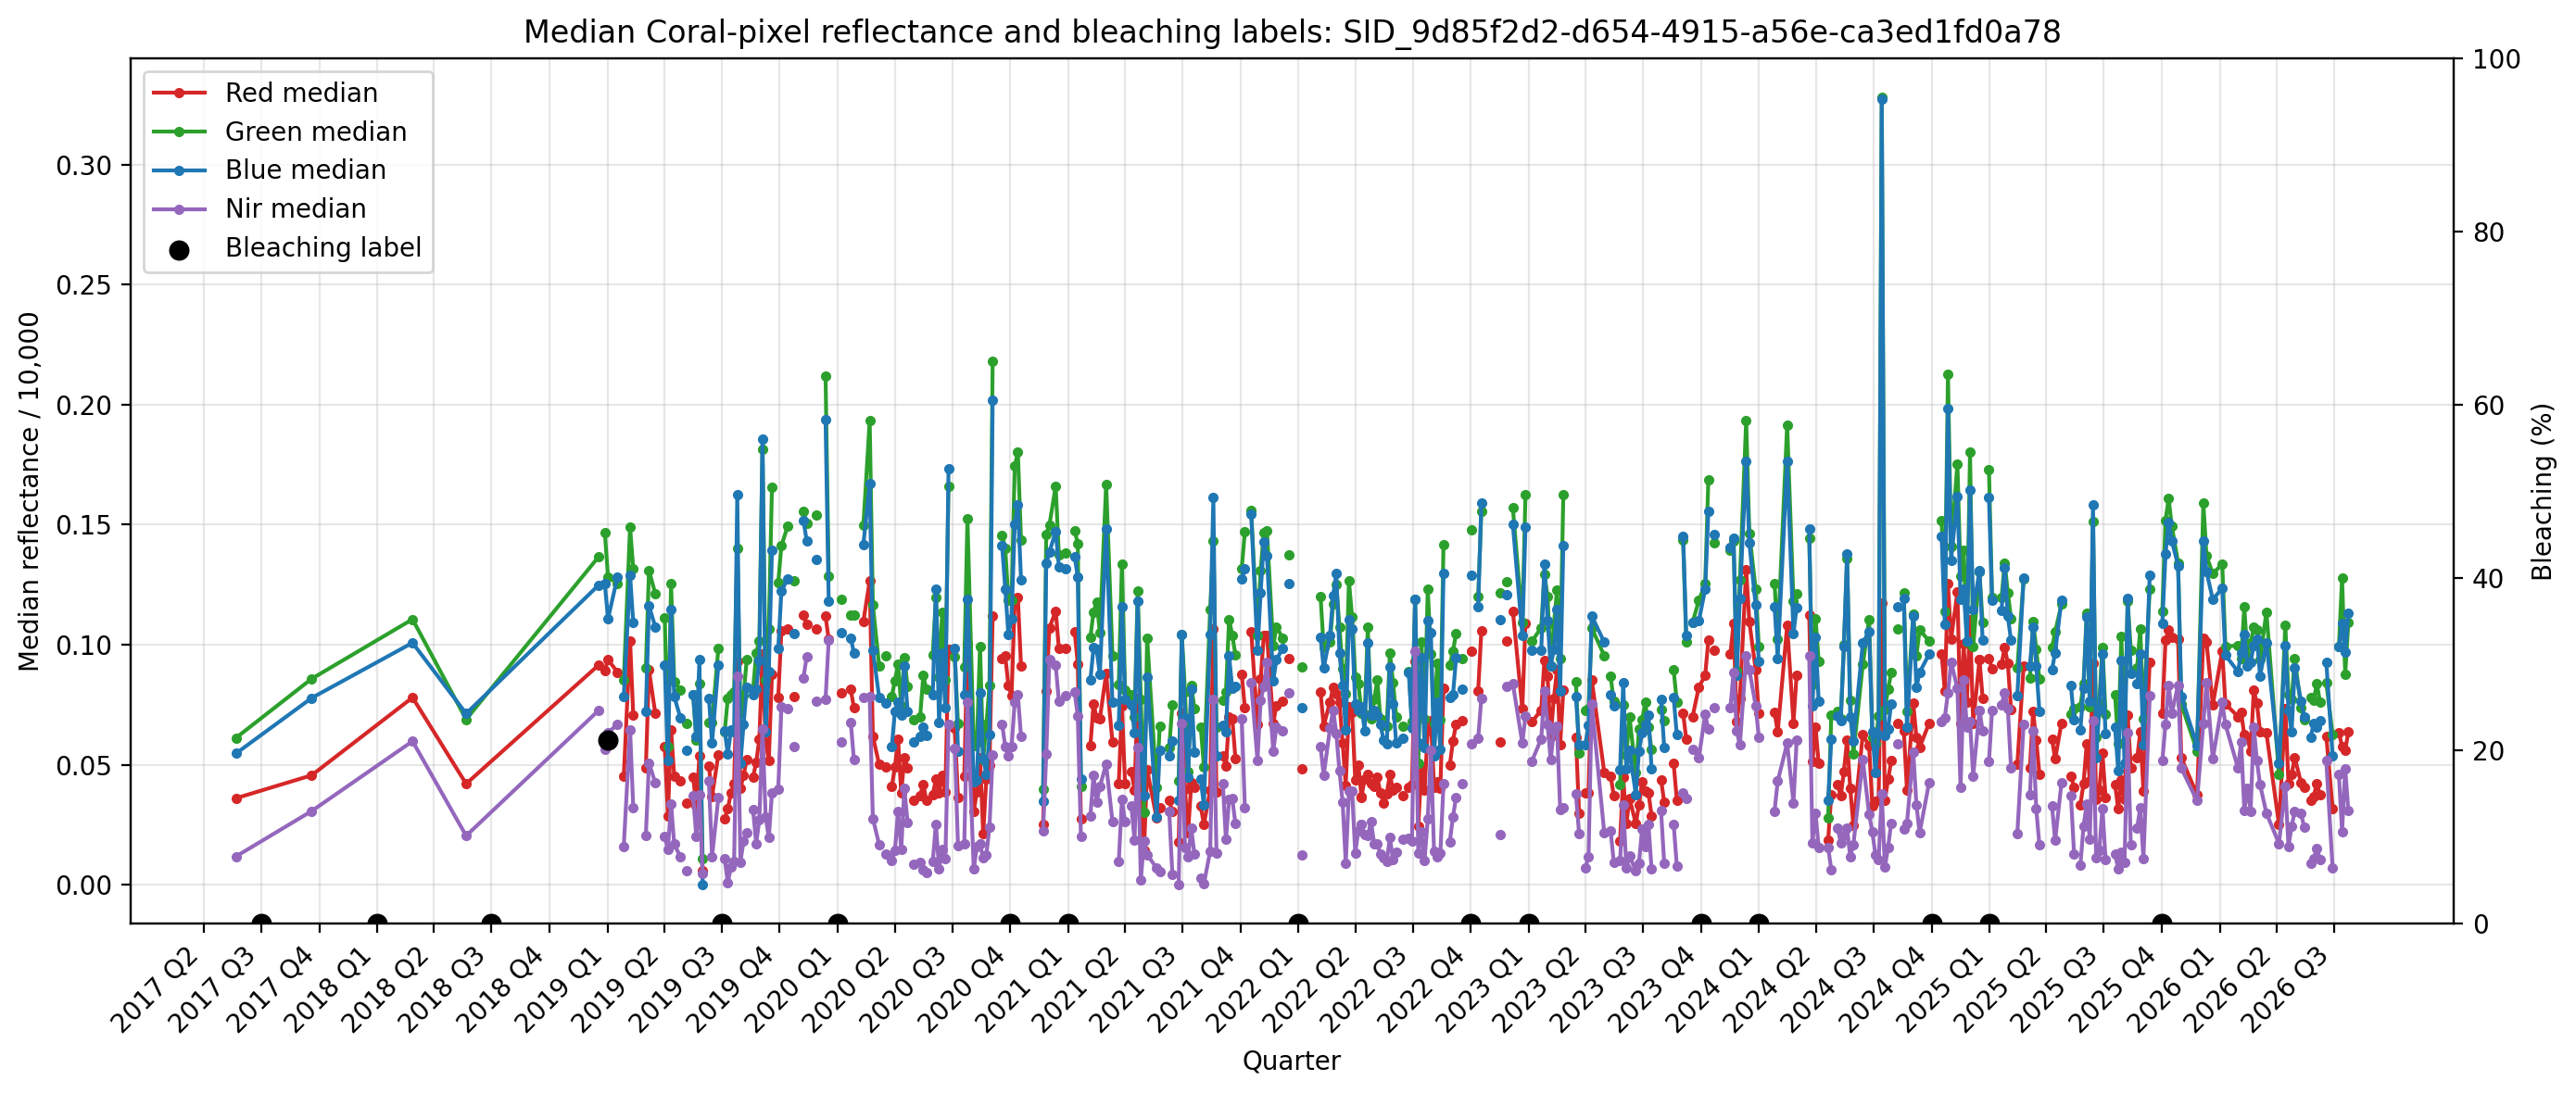

In [113]:

fig, ax = plt.subplots(figsize=(14, 6))

colors = {
    "red": "tab:red",
    "green": "tab:green",
    "blue": "tab:blue",
    "nir": "tab:purple",
}

for channel in ["red", "green", "blue", "nir"]:
    ax.plot(
        summary.index,
        summary[f"{channel}_median"],
        ".-",
        color=colors[channel],
        label=f"{channel.capitalize()} median",
    )

labels_path = (
    r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master"
    r"\Research Practice\Scripts\Labels\sentinellabels_percent.parquet"
)
labels = pd.read_parquet(labels_path)

label_series = labels.loc[SID].copy()
label_series.index = pd.to_datetime(label_series.index)
label_series = pd.to_numeric(label_series, errors="coerce").dropna()



ax_bleaching = ax.twinx()
ax_bleaching.scatter(
    label_series.index,
    label_series.values,
    color="black",
    edgecolors="black",
    linewidths=0.5,
    s=55,
    zorder=5,
    label="Bleaching label",
)

ax_bleaching.set_ylim(0, 100)
ax_bleaching.set_ylabel("Bleaching (%)", color="black")
ax_bleaching.tick_params(axis="y", labelcolor="black")
ax_bleaching.patch.set_visible(False)

quarter_start = summary.index.min().to_period("Q").start_time
quarter_end = summary.index.max().to_period("Q").start_time
quarter_dates = pd.date_range(quarter_start, quarter_end, freq="QS")

ax.set_xticks(quarter_dates)
ax.set_xticklabels(
    [f"{date.year} Q{date.quarter}" for date in quarter_dates],
    rotation=45,
    ha="right",
)

ax.set_xlabel("Quarter")
ax.set_ylabel("Median reflectance / 10,000")
ax.set_title(f"Median Coral-pixel reflectance and bleaching labels: {SID}")

# Combine legends from both y-axes.
handles_left, labels_left = ax.get_legend_handles_labels()
handles_right, labels_right = ax_bleaching.get_legend_handles_labels()
ax.legend(
    handles_left + handles_right,
    labels_left + labels_right,
    loc="upper left",
)

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Within-quarter variability for representative coral pixel examples

Plot 5 representative coral pixels timeseries to check for within quarter variability and glint (common spike in nir and vis)

In [114]:
# find valid coral pixels

year = 2019 # choose exemplary year for analysis
df_2024 = df.sel(time=df.time.dt.year == year)

bands = ["blue", "green", "red", "nir"] 
data_2024 = (df_2024[bands].to_array(dim="band").stack(pixel=("y", "x")))
benthic = df["benthic"].stack(pixel=("y", "x"))
coral_pixels = benthic == 15

# Outlier if all four bands exceed the threshold in the same observation
outlier_observations = (data_2024 > outlier_threshold).all(dim="band")

# all bands must be valid (>0)
valid_observations = ((data_2024 > 0).all(dim="band") & ~outlier_observations)
valid_count = valid_observations.sum(dim="time")
minimum_valid_observations = int(df_2024.sizes["time"] * 0.5) # min 50% of observations valid

# Reject the entire pixel if it has an outlier in any observation
has_outlier = outlier_observations.any(dim="time")

candidate_pixels = (coral_pixels & (valid_count >= minimum_valid_observations) & ~has_outlier)

In [115]:
# Randomly choose five spatially separated pixels

candidate_coordinates = benthic.pixel.where(candidate_pixels, drop=True).values

# prevent selected pixels from being neighbors
minimum_distance = 300

selected_pixels = []
for coordinate in candidate_coordinates:

    y = coordinate[0]
    x = coordinate[1]
    is_far_enough = True

    # Compare the candidate with every pixel that was already selected.
    for selected_y, selected_x in selected_pixels:

        # Calculate the distance to the already selected pixel.
        distance = np.sqrt((y - selected_y) ** 2 + (x - selected_x) ** 2)
        if distance < minimum_distance:
            is_far_enough = False
            break

    if is_far_enough:
        selected_pixels.append((y, x))

    if len(selected_pixels) == 5:
        break

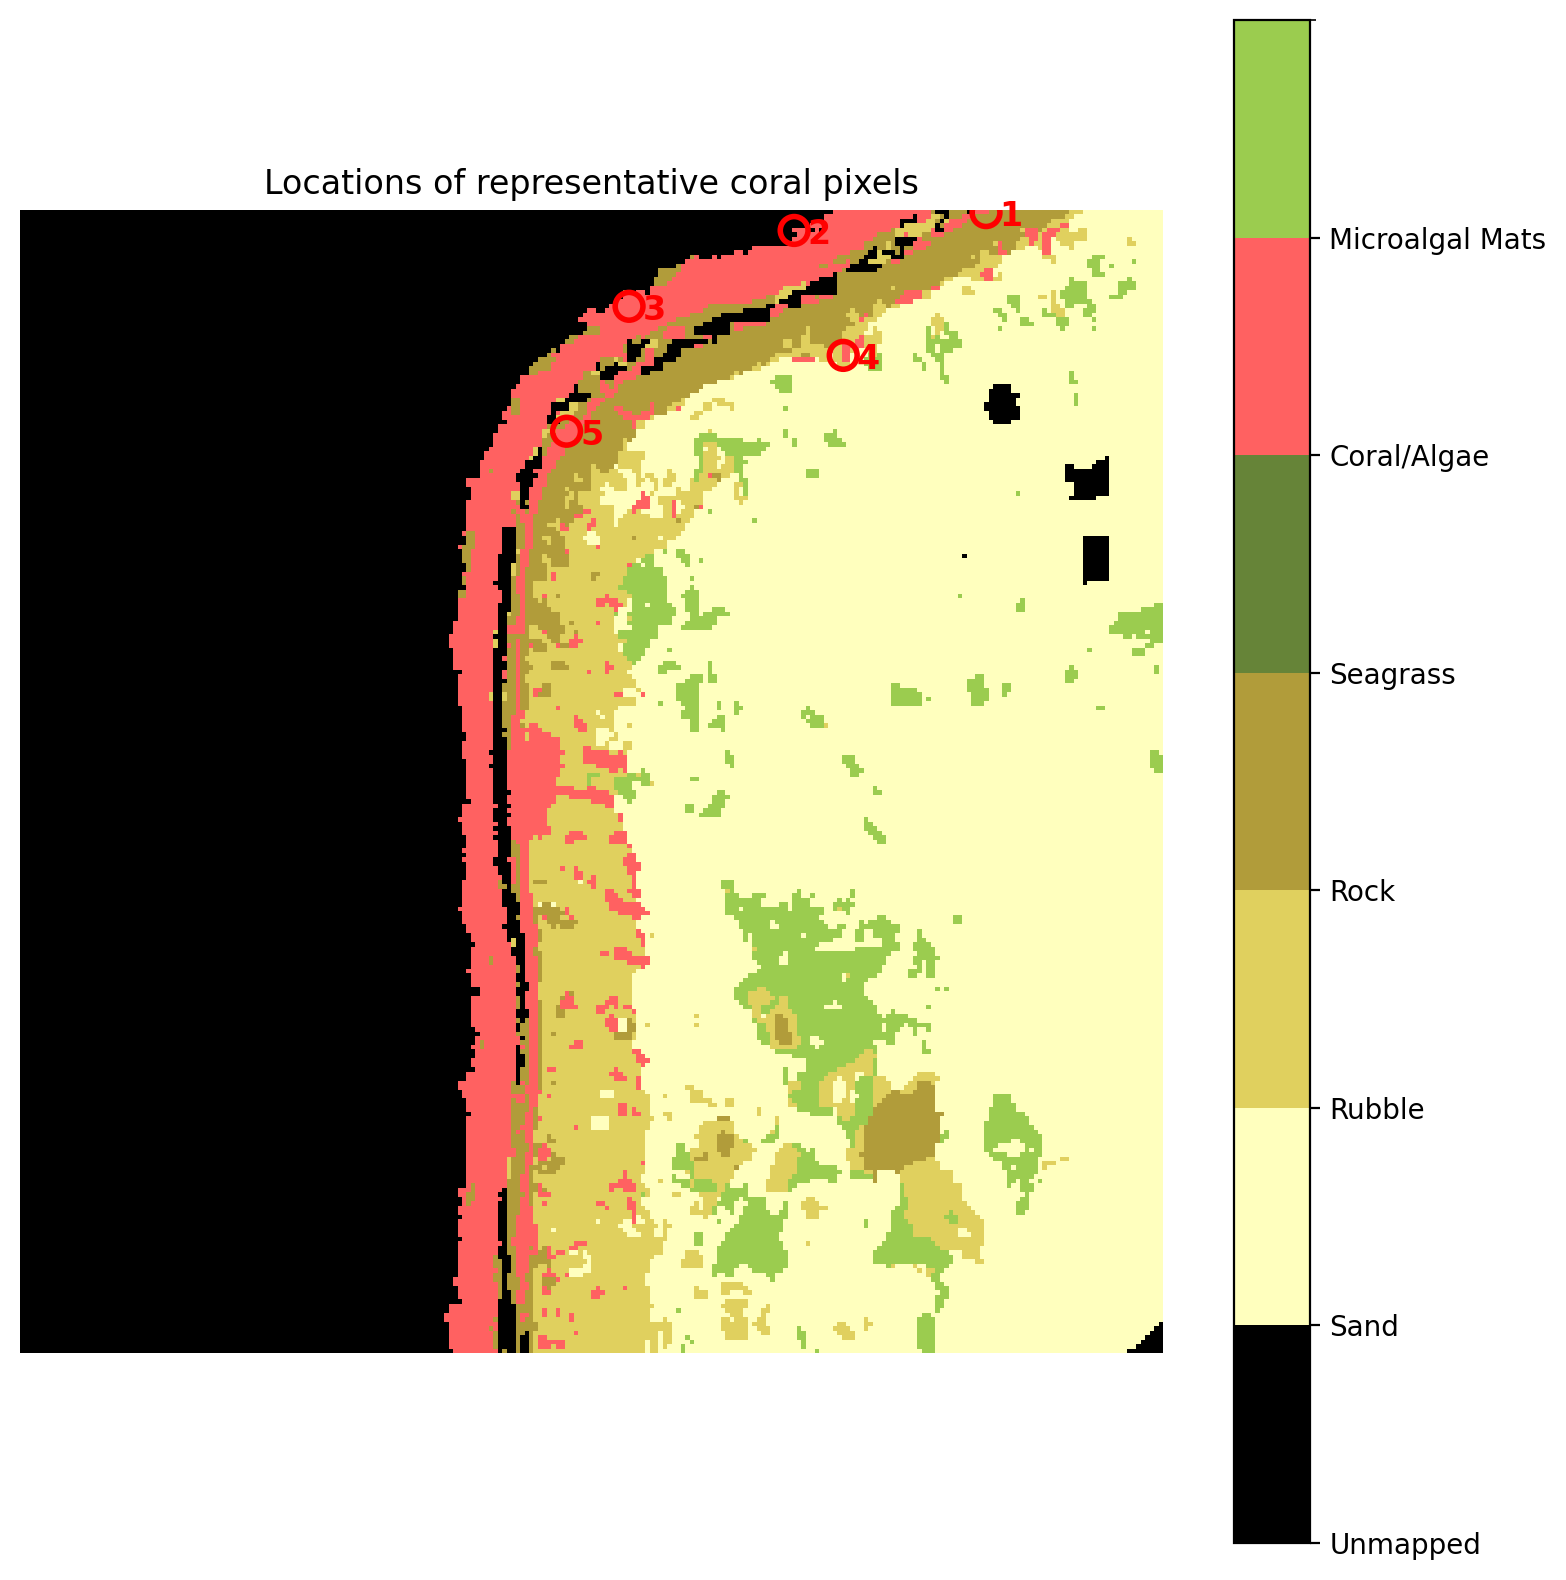

In [116]:
# plot pixel location on image to compare with original rgb images

benthic_image = df["benthic"].squeeze().transpose("y", "x")

y_index = benthic_image.get_index("y")
x_index = benthic_image.get_index("x")

fig, ax = plt.subplots(figsize=(8, 8))

image = ax.imshow(
    benthic_image.values,
    origin="upper",
    cmap=cmap,
    norm=norm,
    interpolation="nearest",
)

for number, (y, x) in enumerate(selected_pixels, start=1):
    y_position = y_index.get_loc(y)
    x_position = x_index.get_loc(x)

    ax.scatter(
        x_position,
        y_position,
        s=100,
        facecolors="none",
        edgecolors="red",
        linewidths=2,
    )

    ax.text(
        x_position + 3,
        y_position + 3,
        str(number),
        fontsize=12,
        fontweight="bold",
        color="red",
    )

ax.set_title("Locations of representative coral pixels")
ax.axis("off")

colorbar = fig.colorbar(image, ax=ax, ticks=classes)
colorbar.ax.set_yticklabels([
    "Unmapped",
    "Sand",
    "Rubble",
    "Rock",
    "Seagrass",
    "Coral/Algae",
    "Microalgal Mats",
])

plt.tight_layout()
plt.show()

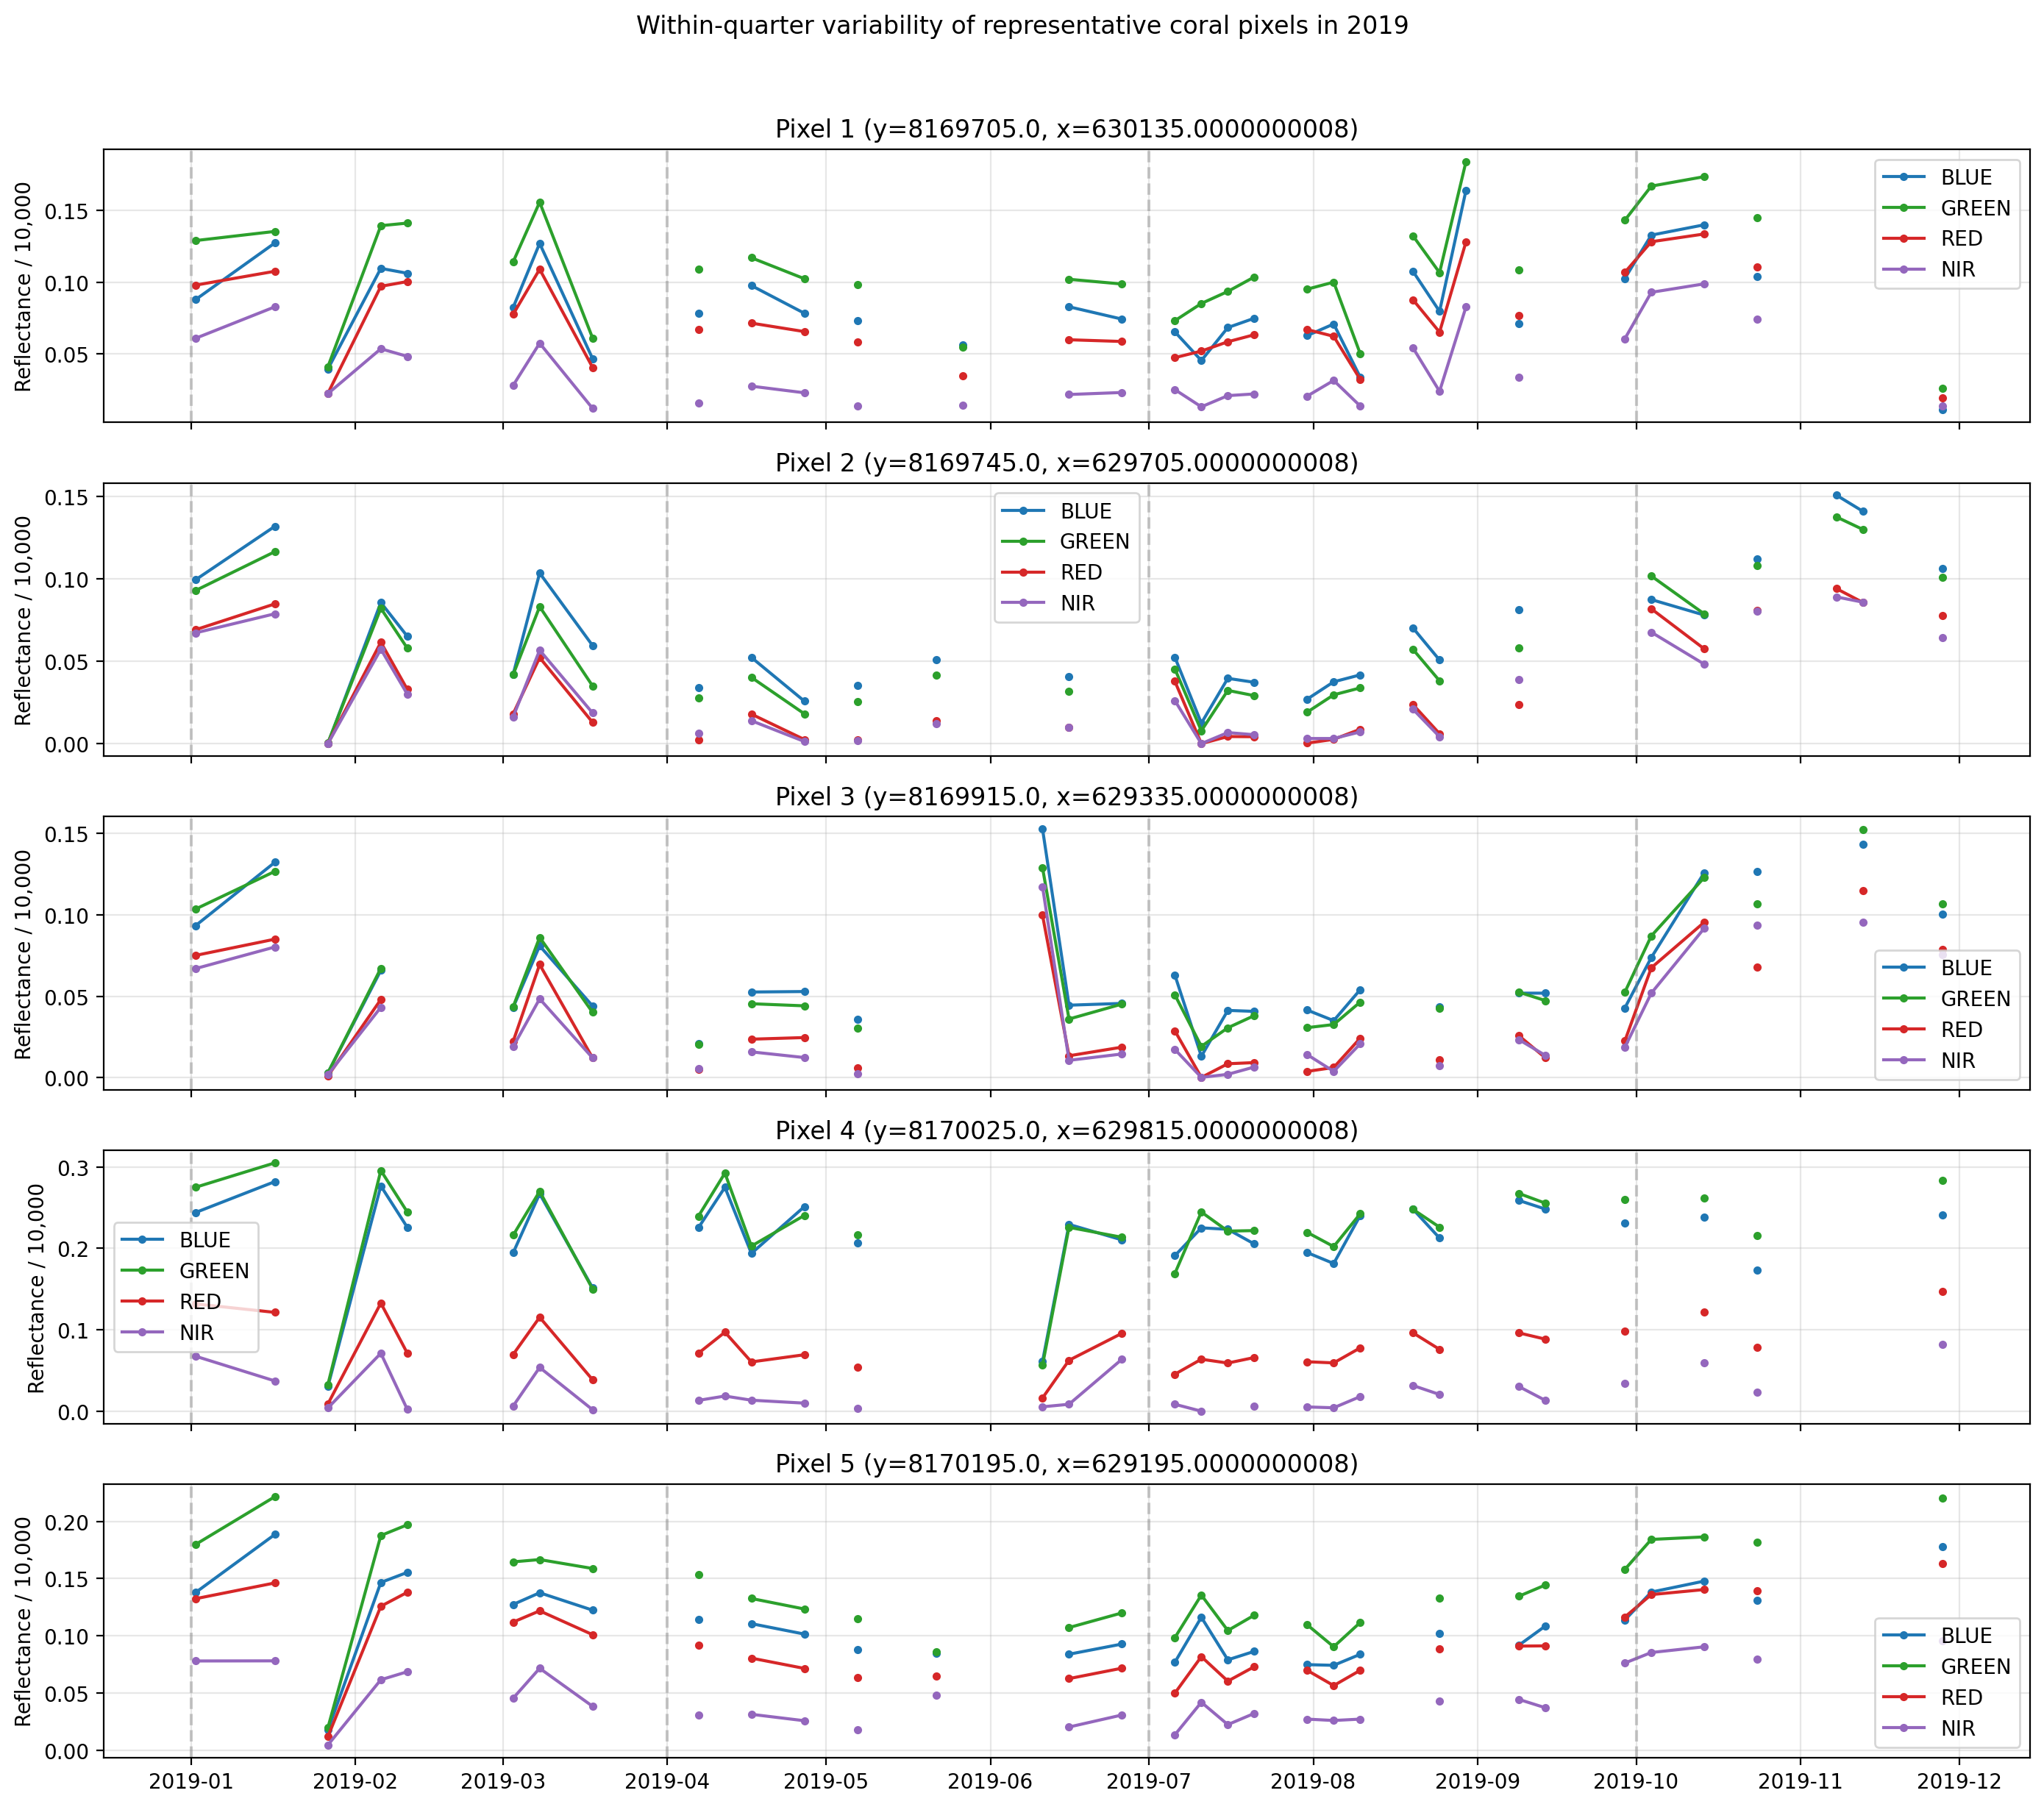

In [117]:
colors = {
    "blue": "tab:blue",
    "green": "tab:green",
    "red": "tab:red",
    "nir": "tab:purple",
}

quarter_dates = pd.date_range(
    start=f"{year}-01-01",
    end=f"{year}-12-31",
    freq="QS",
)

# Create one subplot for every selected pixel
fig, axes = plt.subplots(
    len(selected_pixels),
    1,
    figsize=(14, 12),
    sharex=True,
    squeeze=False,
)

axes = axes[:, 0]

for number, (ax, (y, x)) in enumerate(zip(axes, selected_pixels), start=1):

    pixel_data = data_2024.sel(pixel=(y, x))
    for channel in bands:

        # Replace invalid zero values with NaN
        band_data = pixel_data.sel(band=channel)
        values = band_data.where(band_data > 0) / 10000

        ax.plot(
            pixel_data.time,
            values,
            ".-",
            color=colors[channel],
            label=channel.upper(),
        )

    for quarter_date in quarter_dates:
        ax.axvline(
            quarter_date,
            linestyle="--",
            color="gray",
            alpha=0.4,
        )

    ax.set_title(f"Pixel {number} (y={y}, x={x})")
    ax.set_ylabel("Reflectance / 10,000")
    ax.grid(True, alpha=0.3)

    ax.legend()



fig.suptitle(
    f"Within-quarter variability of representative coral pixels in {year}",
    y=1.02,
)

plt.tight_layout()
plt.show()

## Visualize overlapping sites to choose edge size

In [118]:
from pyproj import Transformer
from datetime import datetime, timedelta, timezone


EDGE_SIZE = 256       
RESOLUTION_M = 10
HALF_WIDTH_M = EDGE_SIZE * RESOLUTION_M / 2


def utm_epsg(lat, lon):
    zone = int((lon + 180) // 6) + 1
    return 32600 + zone if lat >= 0 else 32700 + zone


cube_features = []
site_features = []

for row in regions.itertuples(index=False):
    site_id = str(row.Site_ID)
    lat = float(row.lat)
    lon = float(row.lon)

    epsg = utm_epsg(lat, lon)

    to_utm = Transformer.from_crs(
        "EPSG:4326",
        f"EPSG:{epsg}",
        always_xy=True,
    )
    from_utm = Transformer.from_crs(
        f"EPSG:{epsg}",
        "EPSG:4326",
        always_xy=True,
    )

    center_x, center_y = to_utm.transform(lon, lat)

    corners_utm = [
        (center_x - HALF_WIDTH_M, center_y - HALF_WIDTH_M),
        (center_x + HALF_WIDTH_M, center_y - HALF_WIDTH_M),
        (center_x + HALF_WIDTH_M, center_y + HALF_WIDTH_M),
        (center_x - HALF_WIDTH_M, center_y + HALF_WIDTH_M),
        (center_x - HALF_WIDTH_M, center_y - HALF_WIDTH_M),
    ]

    corners_lon_lat = [
        list(from_utm.transform(x, y))
        for x, y in corners_utm
    ]

    cube_features.append(
        ee.Feature(
            ee.Geometry.Polygon([corners_lon_lat]),
            {
                "site_id": site_id,
                "edge_size_px": EDGE_SIZE,
                "edge_size_m": EDGE_SIZE * RESOLUTION_M,
            },
        )
    )

    site_features.append(
        ee.Feature(
            ee.Geometry.Point([lon, lat]),
            {
                "site_id": site_id,
                "sid": f"SID_{site_id}",
            },
        )
    )

cube_collection = ee.FeatureCollection(cube_features)
site_collection = ee.FeatureCollection(site_features)

Map = geemap.Map()
Map.centerObject(site_collection, 5)

end_date = datetime.now(timezone.utc)
start_date = end_date - timedelta(days=365)

sentinel_collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(cube_collection.geometry())
    .filterDate(start_date, end_date)
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
    .sort("system:time_start", False)
)

sentinel_image = ee.Image(sentinel_collection.first())

Map.addLayer(
    sentinel_image,
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 3000,
    },
    "Latest cloud-free Sentinel-2 RGB",
)

Map.addLayer(
    cube_collection.style(
        color="red",
        fillColor="FF000033",
        width=2,
    ),
    {},
    f"Cube boundaries ({EDGE_SIZE} px)",
)

Map.addLayer(
    site_collection.style(
        color="blue",
        pointSize=6,
    ),
    {},
    "Site centers",
)

#Map.add_labels(
#    site_collection,
#    "sid",
#    font_size="10pt",
#    text_color="blue",
 #   font_weight="bold",
#)

Map

Map(center=[-17.2233067183515, -157.12983608017683], controls=(WidgetControl(options=['position', 'transparent…